# Análisis Exploratorio de Datos (EDA) - Fashion-MNIST

Este notebook presenta un análisis exploratorio completo del dataset **Fashion-MNIST**. Este conjunto de datos contiene imágenes de artículos de Zalando y está diseñado como un reemplazo directo para el dataset MNIST clásico.

## Contenido
1.  Carga de librerías y configuración
2.  Descarga y carga de datos
3.  Información básica del dataset
4.  Visualización de muestras aleatorias
5.  Distribución de clases
6.  Análisis de intensidad de píxeles
7.  Imagen promedio por clase
8.  Conclusiones

## 1. Carga de librerías y configuración

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Configuración para gráficos
plt.style.use('ggplot')
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Descarga y carga de datos

Utilizaremos `torchvision` para descargar el dataset. Fashion-MNIST consta de 60,000 imágenes de entrenamiento y 10,000 de prueba.

In [2]:
# Definir transformación básica a tensor
transform = transforms.Compose([transforms.ToTensor()])

# Descargar datasets de entrenamiento y prueba
trainset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# Definir las etiquetas de las clases (mapping)
classes = (
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle Boot'
)

print("Datos descargados y cargados.")

100%|██████████| 26421880/26421880 [00:02<00:00, 12864815.96it/s]


Extracting ./data\FashionMNIST\raw\train-images-idx3-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 29515/29515 [00:00<00:00, 576425.56it/s]


Extracting ./data\FashionMNIST\raw\train-labels-idx1-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 4422102/4422102 [00:00<00:00, 6512559.82it/s]


Extracting ./data\FashionMNIST\raw\t10k-images-idx3-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 5148/5148 [00:00<00:00, 1257411.89it/s]

Extracting ./data\FashionMNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\FashionMNIST\raw



Datos descargados y cargados.


## 3. Información básica del dataset

Vamos a inspeccionar las dimensiones de los datos y verificar que se hayan cargado correctamente.

In [3]:
print(f"Número de imágenes de entrenamiento: {len(trainset)}")
print(f"Número de imágenes de prueba: {len(testset)}")

# Inspeccionar una imagen
image, label = trainset[0]
print(f"Dimensiones de la imagen: {image.shape} (Canales, Alto, Ancho)")
print(f"Tipo de dato: {image.dtype}")
print(f"Rango de valores: [{image.min():.2f}, {image.max():.2f}]")

Número de imágenes de entrenamiento: 60000
Número de imágenes de prueba: 10000
Dimensiones de la imagen: torch.Size([1, 28, 28]) (Canales, Alto, Ancho)
Tipo de dato: torch.float32
Rango de valores: [0.00, 1.00]


## 4. Visualización de muestras aleatorias

Es fundamental visualizar los datos para entender con qué estamos trabajando. Mostraremos una cuadrícula de imágenes aleatorias.

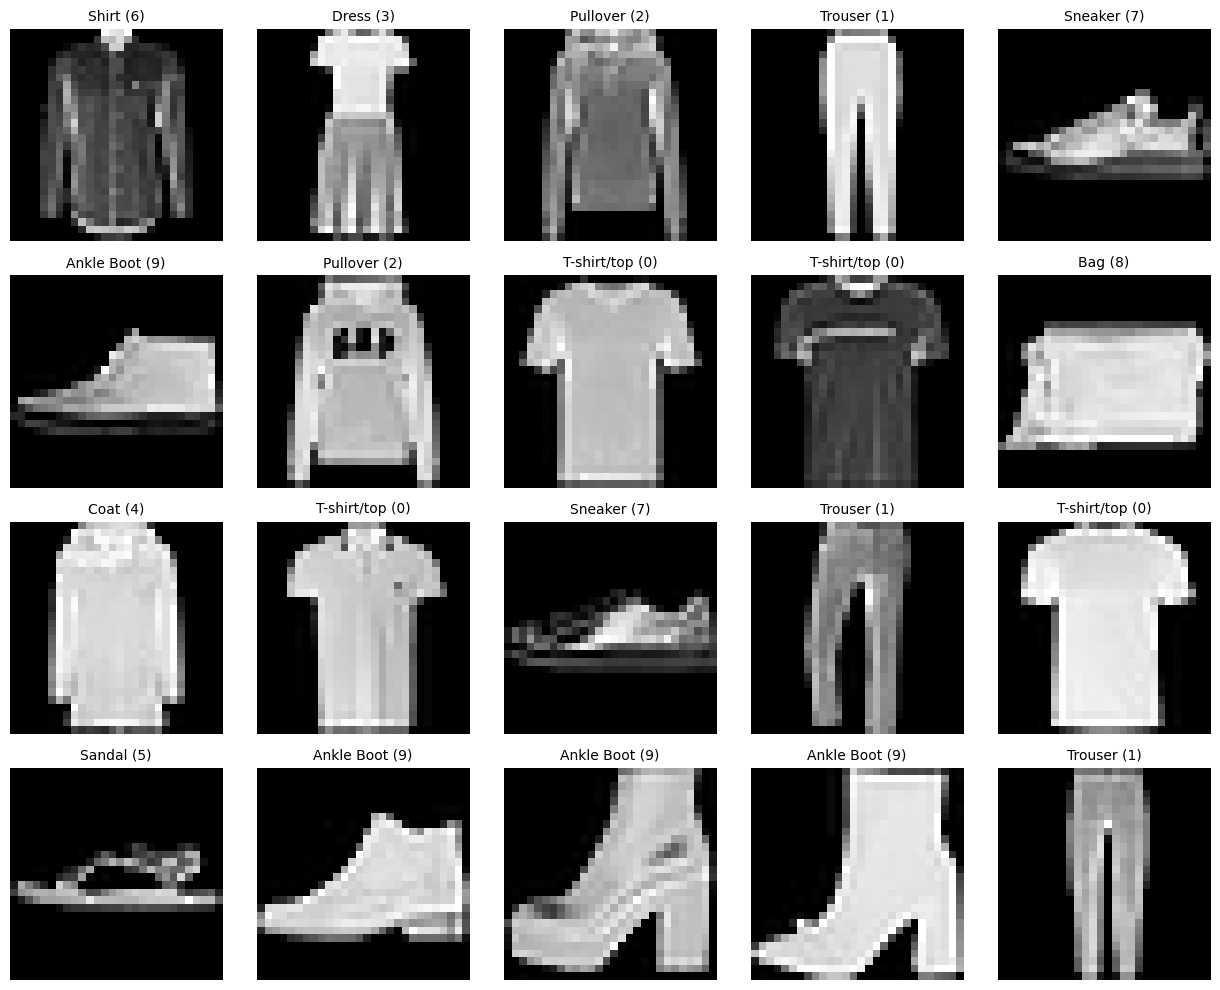

In [4]:
def show_samples(dataset, num_samples=20, cols=5):
    indices = torch.randperm(len(dataset))[:num_samples]
    rows = (num_samples + cols - 1) // cols
    
    plt.figure(figsize=(cols * 2.5, rows * 2.5))
    for i, idx in enumerate(indices):
        image, label = dataset[idx]
        image = image.numpy().squeeze() # Eliminar dimensión de canal para visualización
        
        plt.subplot(rows, cols, i + 1)
        plt.imshow(image, cmap='gray')
        plt.title(f"{classes[label]} ({label})", fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

show_samples(trainset)

## 5. Distribución de clases

Verificaremos si el dataset está balanceado. En Fashion-MNIST, esperamos tener exactamente 6,000 imágenes por clase en el conjunto de entrenamiento.

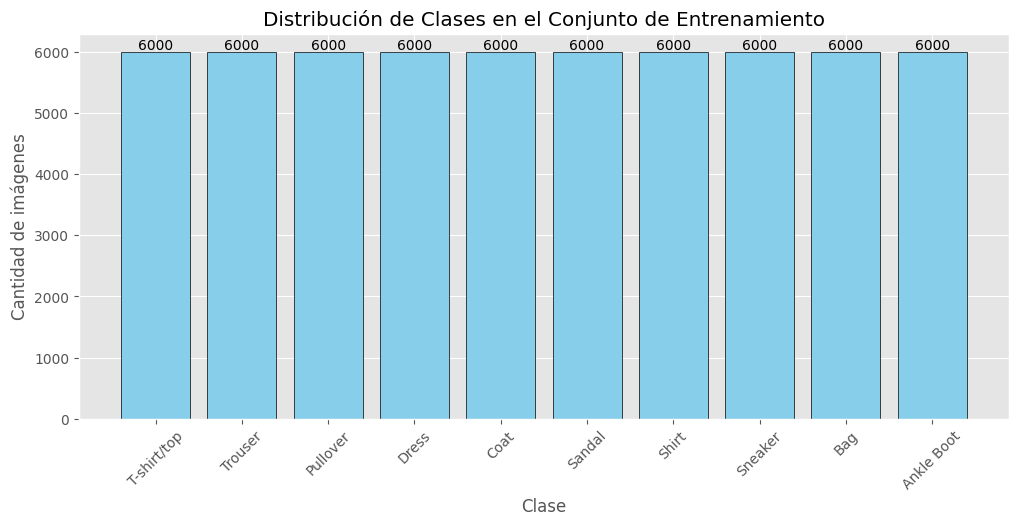

In [5]:
train_labels = trainset.targets.numpy()
label_counts = Counter(train_labels)

labels = [classes[i] for i in range(10)]
counts = [label_counts[i] for i in range(10)]

plt.figure(figsize=(12, 5))
bars = plt.bar(labels, counts, color='skyblue', edgecolor='black')
plt.xlabel('Clase')
plt.ylabel('Cantidad de imágenes')
plt.title('Distribución de Clases en el Conjunto de Entrenamiento')
plt.xticks(rotation=45)

# Añadir etiquetas de valor
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom')

plt.show()

## 6. Análisis de intensidad de píxeles

Analizaremos la distribución de los valores de los píxeles. Esto nos ayuda a saber si necesitamos normalizar los datos (aunque ya sabemos que están entre 0 y 1 o 0 y 255).

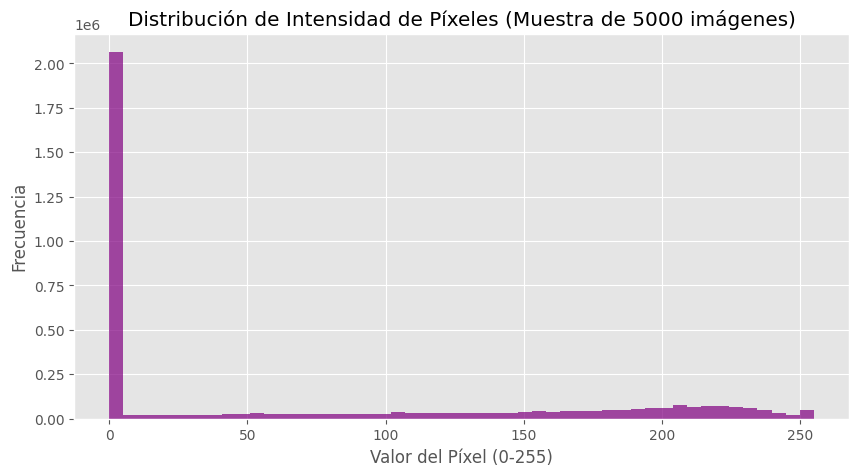

In [6]:
# Tomamos una muestra representativa para no sobrecargar la memoria
sample_indices = torch.randperm(len(trainset))[:5000]
sample_images = trainset.data[sample_indices].float().numpy().flatten()

plt.figure(figsize=(10, 5))
plt.hist(sample_images, bins=50, color='purple', alpha=0.7)
plt.title('Distribución de Intensidad de Píxeles (Muestra de 5000 imágenes)')
plt.xlabel('Valor del Píxel (0-255)')
plt.ylabel('Frecuencia')
plt.show()

## 7. Imagen promedio por clase

Una técnica interesante es calcular la "imagen promedio" para cada clase. Esto nos revela la estructura común de cada tipo de prenda (por ejemplo, la forma general de un pantalón o una camiseta).

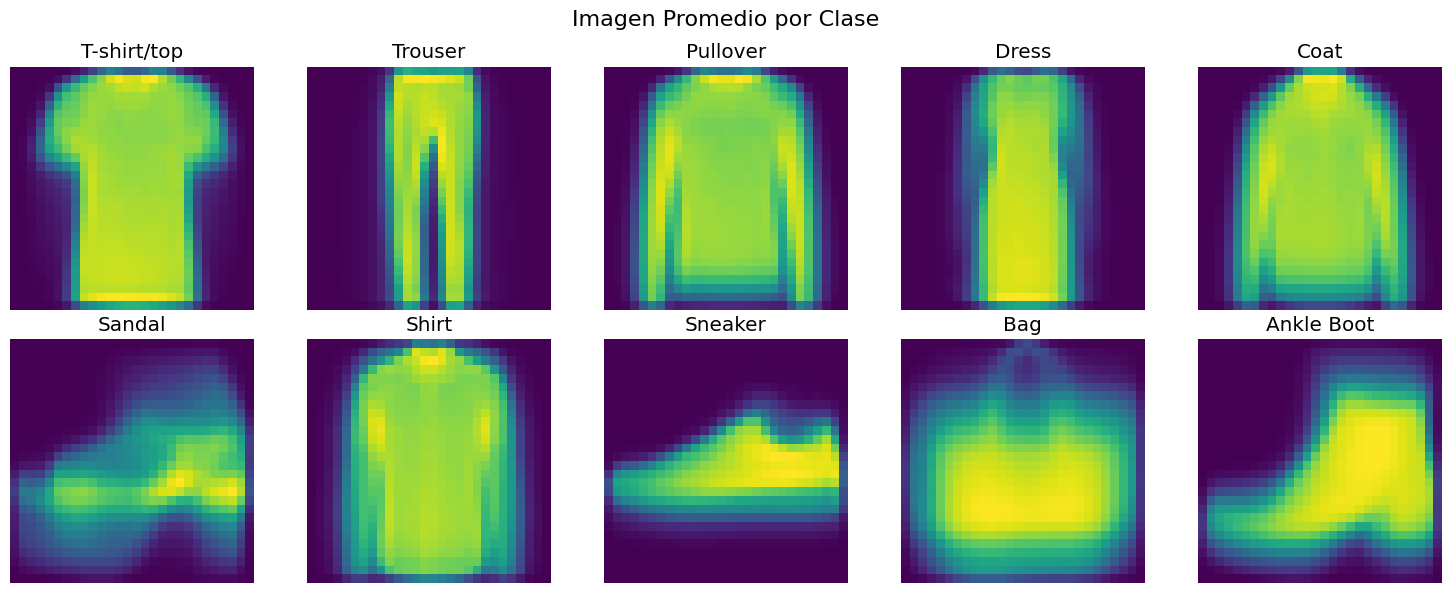

In [7]:
def show_average_images(dataset):
    # Agrupar imágenes por clase
    class_images = {i: [] for i in range(10)}
    
    # Usamos todo el dataset (puede tardar unos segundos)
    images = dataset.data.float().numpy()
    labels = dataset.targets.numpy()
    
    for i in range(10):
        class_imgs = images[labels == i]
        mean_img = np.mean(class_imgs, axis=0)
        class_images[i] = mean_img

    plt.figure(figsize=(15, 6))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(class_images[i], cmap='viridis') # Viridis resalta bien las diferencias de intensidad
        plt.title(classes[i])
        plt.axis('off')
    
    plt.suptitle('Imagen Promedio por Clase', fontsize=16)
    plt.tight_layout()
    plt.show()

show_average_images(trainset)

## 8. Conclusiones

- **Balance**: El dataset está perfectamente balanceado (6,000 imágenes por clase).
- **Resolución**: Las imágenes son pequeñas (28x28) y en escala de grises.
- **Dificultad**: A diferencia de MNIST (dígitos), Fashion-MNIST presenta mayor complejidad visual (texturas, formas variables de ropa), lo que lo hace un mejor benchmark para algoritmos modernos.
- **Patrones**: Las imágenes promedio muestran siluetas claras, lo que indica que las prendas están centradas y tienen una estructura consistente.